# EEG Depression Classification — AdaBoost 71.4% Experiment

**Purpose:** Reproduce the AdaBoost experiment that previously achieved **71.43% accuracy** on the 14-participant holdout set.

**Dataset:** MODMA 3-channel resting EEG  
**Channels:** Fp1, Fpz, Fp2  
**Sampling rate:** 250 Hz  
**Labels:** HC = 0, MDD = 1

## Important: this notebook reproduces the earlier experiment

This notebook deliberately uses the same workflow that produced the earlier 71.43% result:

1. Extract the same 51 EEG features per participant.
2. Use the same stratified train/test split: `test_size=0.25`, `random_state=42`.
3. Use the same AdaBoost + DecisionTree pipeline.
4. Use the same GridSearchCV parameter grid and 5-fold CV.
5. Evaluate the selected model on the 14-person holdout set.

**Do not add `SelectKBest` or change the split/grid if you want to reproduce this experiment.** The earlier 71.43% result used all 51 features, without a feature-selection step.

**Research caution:** The 71.43% result is an exploratory result from a very small test set (7 HC + 7 MDD). The test set has already been examined during model development, so this is not an independent final performance estimate and must not be presented as clinical diagnostic accuracy.

## 1. Install and import libraries

In [1]:
%pip -q install numpy pandas matplotlib scipy scikit-learn openpyxl joblib

In [2]:
import os
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from scipy.signal import butter, sosfiltfilt, welch
from scipy.stats import skew, kurtosis
from scipy.integrate import trapezoid

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

RANDOM_STATE = 42
SAMPLING_RATE = 250
CHANNEL_NAMES = ["Fp1", "Fpz", "Fp2"]

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload the original dataset ZIP

Upload `854301_EEG_3Channels_Resting_Lanzhou_2015(1).zip` when prompted. Alternatively, put it beside the notebook and set `ZIP_PATH` to its exact path.

In [3]:
ZIP_PATH = "854301_EEG_3Channels_Resting_Lanzhou_2015.zip"

if not os.path.exists(ZIP_PATH):
    for candidate in ["854301_EEG_3Channels_Resting_Lanzhou_2015 (1).zip", "854301_EEG_3Channels_Resting_Lanzhou_2015.zip"]:
        if os.path.exists(candidate):
            ZIP_PATH = candidate
            break

if not os.path.exists(ZIP_PATH):
    try:
        from google.colab import files
        print("Upload the original MODMA ZIP file.")
        uploaded = files.upload()
        zip_candidates = [name for name in uploaded if name.lower().endswith(".zip")]
        if not zip_candidates:
            raise FileNotFoundError("No ZIP file was uploaded.")
        ZIP_PATH = zip_candidates[0]
    except ImportError:
        raise FileNotFoundError(
            "ZIP file not found. Put it beside this notebook or update ZIP_PATH."
        )

print("Dataset found:", ZIP_PATH)
zip_file = zipfile.ZipFile(ZIP_PATH, "r")

Dataset found: 854301_EEG_3Channels_Resting_Lanzhou_2015.zip


## 3. Load participant labels from the Excel file

The workbook is read directly from the ZIP archive. HC is encoded as 0 and MDD as 1.

In [4]:
excel_files = [
    name for name in zip_file.namelist()
    if name.endswith(".xlsx")
]

if not excel_files:
    raise FileNotFoundError("No Excel metadata file found inside the ZIP.")

excel_name = excel_files[0]
metadata = pd.read_excel(io.BytesIO(zip_file.read(excel_name)))

metadata = metadata[["subject id", "type"]].copy()
metadata = metadata.dropna(subset=["subject id", "type"])
metadata["subject id"] = metadata["subject id"].astype(int)
metadata["type"] = metadata["type"].astype(str).str.strip().str.upper()
metadata["label"] = metadata["type"].map({"HC": 0, "MDD": 1})
metadata = metadata.dropna(subset=["label"])
metadata["label"] = metadata["label"].astype(int)

print("Participants in metadata:", len(metadata))
display(metadata["type"].value_counts().to_frame("participants"))

Participants in metadata: 55


,participants
type,
HC,29
MDD,26


## 4. Match EEG text files to participant IDs

We use the `_still.txt` recordings and match the numeric file prefix to the Excel subject ID.

In [5]:
eeg_files = [
    name for name in zip_file.namelist()
    if name.lower().endswith("_still.txt")
]

eeg_file_by_id = {}

for file_name in eeg_files:
    file_prefix = os.path.basename(file_name).split("_")[0]
    participant_id = int(file_prefix)
    eeg_file_by_id[participant_id] = file_name

recording_rows = []

for participant_id, file_name in eeg_file_by_id.items():
    eeg_data = np.loadtxt(io.BytesIO(zip_file.read(file_name)))

    if eeg_data.ndim != 2 or eeg_data.shape[1] != 3:
        print("Skipping unexpected file format:", file_name, eeg_data.shape)
        continue

    recording_rows.append({
        "subject_id": participant_id,
        "number_of_samples": len(eeg_data),
        "duration_seconds": len(eeg_data) / SAMPLING_RATE
    })

recording_info = pd.DataFrame(recording_rows)

dataset_info = recording_info.merge(
    metadata,
    left_on="subject_id",
    right_on="subject id",
    how="inner"
)

print("EEG text files:", len(eeg_files))
print("Matched participants:", len(dataset_info))
print("Matched class counts:")
display(dataset_info["type"].value_counts())

EEG text files: 55
Matched participants: 55
Matched class counts:


,count
type,
HC,29
MDD,26


## 5. Define EEG loading and preprocessing

The original experiment used a fourth-order Butterworth 1–40 Hz bandpass filter.

In [6]:
def load_eeg_recording(file_name):
    eeg_data = np.loadtxt(io.BytesIO(zip_file.read(file_name)))
    eeg_data = np.asarray(eeg_data, dtype=float)

    if eeg_data.ndim != 2 or eeg_data.shape[1] != 3:
        raise ValueError("Expected an EEG array with exactly 3 columns.")

    if not np.isfinite(eeg_data).all():
        raise ValueError("EEG file contains missing or infinite values.")

    return eeg_data


def preprocess_eeg(eeg_data, sampling_rate=SAMPLING_RATE):
    eeg_data = np.asarray(eeg_data, dtype=float)

    if eeg_data.ndim != 2 or eeg_data.shape[1] != 3:
        raise ValueError("EEG data must have 3 columns.")

    if len(eeg_data) < 20:
        raise ValueError("EEG recording is too short to filter safely.")

    if not np.isfinite(eeg_data).all():
        raise ValueError("EEG data contains missing or infinite values.")

    filter_sos = butter(
        N=4,
        Wn=[1, 40],
        btype="bandpass",
        fs=sampling_rate,
        output="sos"
    )

    filtered_signal = sosfiltfilt(filter_sos, eeg_data, axis=0)
    return filtered_signal

## 6. Extract the same 51 EEG features

This is the same feature extraction used for the earlier 71.43% AdaBoost experiment: 17 features per channel × 3 channels = 51 features.

In [7]:
def extract_eeg_features(eeg_data, sampling_rate=SAMPLING_RATE):
    filtered_signal = preprocess_eeg(eeg_data, sampling_rate)

    features = {}

    frequency_bands = {
        "delta": (1, 4),
        "theta": (4, 8),
        "alpha": (8, 13),
        "beta": (13, 30),
        "gamma": (30, 40)
    }

    for channel_number, channel_name in enumerate(CHANNEL_NAMES):
        channel_signal = filtered_signal[:, channel_number]

        features[channel_name + "_mean"] = np.mean(channel_signal)
        features[channel_name + "_std"] = np.std(channel_signal)
        features[channel_name + "_variance"] = np.var(channel_signal)
        features[channel_name + "_rms"] = np.sqrt(np.mean(channel_signal ** 2))
        features[channel_name + "_peak_to_peak"] = np.ptp(channel_signal)
        features[channel_name + "_skewness"] = skew(channel_signal)
        features[channel_name + "_kurtosis"] = kurtosis(channel_signal)

        samples_per_segment = min(len(channel_signal), sampling_rate * 4)

        frequencies, power_spectrum = welch(
            channel_signal,
            fs=sampling_rate,
            nperseg=samples_per_segment
        )

        band_powers = {}

        for band_name, (low_frequency, high_frequency) in frequency_bands.items():
            band_mask = (
                (frequencies >= low_frequency) &
                (frequencies < high_frequency)
            )

            if np.sum(band_mask) >= 2:
                band_power = trapezoid(
                    power_spectrum[band_mask],
                    frequencies[band_mask]
                )
            else:
                band_power = 0.0

            band_powers[band_name] = band_power
            features[channel_name + "_" + band_name + "_power"] = band_power

        total_band_power = sum(band_powers.values()) + 1e-12

        for band_name, band_power in band_powers.items():
            features[channel_name + "_" + band_name + "_relative_power"] = (
                band_power / total_band_power
            )

    return features


print("EEG preprocessing and feature extraction functions are ready.")

EEG preprocessing and feature extraction functions are ready.


## 7. Extract features for all participants

Keep the same order as the ZIP file listing, matching the original notebook workflow.

In [8]:
feature_rows = []

for participant_id, file_name in eeg_file_by_id.items():
    participant_row = metadata[metadata["subject id"] == participant_id]

    if participant_row.empty:
        print("No label found for participant:", participant_id)
        continue

    participant_group = participant_row.iloc[0]["type"]
    participant_label = int(participant_row.iloc[0]["label"])

    eeg_data = load_eeg_recording(file_name)
    features = extract_eeg_features(eeg_data)

    features["subject_id"] = participant_id
    features["group"] = participant_group
    features["label"] = participant_label

    feature_rows.append(features)

feature_df = pd.DataFrame(feature_rows)

first_columns = ["subject_id", "group", "label"]
other_columns = [
    column for column in feature_df.columns
    if column not in first_columns
]
feature_df = feature_df[first_columns + other_columns]

print("Feature table shape:", feature_df.shape)
print("Participants:", len(feature_df))
print("EEG predictors:", len(other_columns))
display(feature_df.head())

Feature table shape: (55, 54)
Participants: 55
EEG predictors: 51


,subject_id,group,label,Fp1_mean,Fp1_std,Fp1_variance,Fp1_rms,Fp1_peak_to_peak,Fp1_skewness,Fp1_kurtosis,...,Fp2_delta_power,Fp2_theta_power,Fp2_alpha_power,Fp2_beta_power,Fp2_gamma_power,Fp2_delta_relative_power,Fp2_theta_relative_power,Fp2_alpha_relative_power,Fp2_beta_relative_power,Fp2_gamma_relative_power
0,2010001,MDD,1,-3.433851,1393.625102,1.942191e+06,1393.629332,97104.652249,-0.974880,86.828429,...,247155.243308,228181.981714,122529.171609,104917.032744,14755.452262,0.344449,0.318006,0.170763,0.146218,0.020564
1,2010002,MDD,1,-3.532619,1666.118815,2.775952e+06,1666.122560,58963.331617,-0.734042,14.347199,...,133145.752993,26842.922112,48641.871576,22220.396434,4962.693873,0.564623,0.113831,0.206273,0.094229,0.021045
2,2010003,MDD,1,0.642106,1872.622177,3.506714e+06,1872.622287,323207.549416,-0.149734,3058.848959,...,763439.606138,173897.852391,99860.273474,68730.593556,8336.341391,0.685151,0.156065,0.089620,0.061682,0.007481
3,2010005,MDD,1,-1.336686,995.016475,9.900578e+05,995.017373,33194.451194,-0.334771,7.816664,...,615370.191157,103470.324149,54669.598392,49214.118981,10847.116066,0.738233,0.124129,0.065585,0.059040,0.013013
4,2010006,MDD,1,-2.378962,1950.929847,3.806127e+06,1950.931297,61854.473850,0.181035,5.712261,...,411492.388746,42339.714756,81282.222627,47239.356642,12370.353593,0.691905,0.071192,0.136672,0.079431,0.020800


## 8. Handle missing/infinite feature values exactly as in the earlier workflow

The earlier notebook replaced infinite values with NaN and filled numeric columns with their medians before splitting. We retain this step here specifically to reproduce the historical experiment. Note that this preprocessing-before-split can introduce information leakage; the result should therefore be treated as exploratory, not as an unbiased estimate.

In [9]:
print("Missing values before handling:", feature_df.isnull().sum().sum())

feature_df = feature_df.replace([np.inf, -np.inf], np.nan)

if feature_df.isnull().sum().sum() > 0:
    print("Filling missing numeric values with column medians.")

    numeric_feature_columns = feature_df.select_dtypes(include=[np.number]).columns
    feature_df[numeric_feature_columns] = feature_df[numeric_feature_columns].fillna(
        feature_df[numeric_feature_columns].median()
    )

print("Missing values after handling:", feature_df.isnull().sum().sum())
print("Class counts:")
display(feature_df["group"].value_counts())

Missing values before handling: 0
Missing values after handling: 0
Class counts:


,count
group,
HC,29
MDD,26


## 9. Create X and y

Use only the 51 EEG-derived feature columns. Subject ID, group text and label are not predictors.

In [10]:
X = feature_df.drop(columns=["subject_id", "group", "label"])
y = feature_df["label"].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target counts (0 = HC, 1 = MDD):")
display(y.value_counts().sort_index())

X shape: (55, 51)
y shape: (55,)
Target counts (0 = HC, 1 = MDD):


,count
label,
0,29
1,26


## 10. Recreate the original stratified train/test split

This exact split is important for reproducing the earlier result:

- `test_size=0.25`
- `random_state=42`
- `stratify=y`

With 55 participants, this gives 41 training participants and 14 test participants (7 HC and 7 MDD).

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training participants:", len(X_train))
print("Testing participants:", len(X_test))

print("\nTraining class counts:")
display(y_train.value_counts().sort_index())

print("\nTesting class counts:")
display(y_test.value_counts().sort_index())

Training participants: 41
Testing participants: 14

Training class counts:


,count
label,
0,22
1,19



Testing class counts:


,count
label,
0,7
1,7


## 11. Create the exact AdaBoost pipeline used for the 71.43% result

**Do not add `SelectKBest` here.** The earlier 71.43% experiment used all 51 features.

In [12]:
ada_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        random_state=42
    ))
])

print(ada_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=42),
                                    random_state=42))])


## 12. Define the original GridSearchCV parameter grid

The search tests 40 combinations:

- Number of estimators: 25, 50, 100, 200
- Learning rate: 0.01, 0.05, 0.1, 0.5, 1.0
- Decision-tree max depth: 1, 2

In [13]:
ada_param_grid = {
    "model__n_estimators": [25, 50, 100, 200],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0],
    "model__estimator__max_depth": [1, 2]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Number of parameter combinations:",
      len(ada_param_grid["model__n_estimators"]) *
      len(ada_param_grid["model__learning_rate"]) *
      len(ada_param_grid["model__estimator__max_depth"]))

Number of parameter combinations: 40


## 13. Run GridSearchCV on the 41 training participants

This is the same tuning procedure that produced the earlier best parameters:

- `max_depth = 1`
- `learning_rate = 0.01`
- `n_estimators = 100`

Run this cell to verify the result on your copy of the dataset.

In [14]:
ada_grid_search = GridSearchCV(
    estimator=ada_pipeline,
    param_grid=ada_param_grid,
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

ada_grid_search.fit(X_train, y_train)

print("\nBest AdaBoost Parameters:")
print(ada_grid_search.best_params_)

print("\nBest Cross-Validation Balanced Accuracy:")
print(ada_grid_search.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits

Best AdaBoost Parameters:
{'model__estimator__max_depth': 1, 'model__learning_rate': 0.01, 'model__n_estimators': 100}

Best Cross-Validation Balanced Accuracy:
0.6699999999999999


## 14. Evaluate the selected model on the 14 held-out participants

The expected historical result was 71.43% accuracy, with this confusion matrix:

```text
[[3, 4],
 [0, 7]]
```

The exact result should be generated by the code, not hard-coded. If your result differs, check that you uploaded the same dataset version and that the ZIP file order, feature extraction code, split and package versions match.

In [15]:
best_ada_model = ada_grid_search.best_estimator_

y_pred_ada = best_ada_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred_ada)
test_balanced_accuracy = balanced_accuracy_score(y_test, y_pred_ada)

print("Selected model: AdaBoost")
print("Test Accuracy:", test_accuracy)
print("Test Balanced Accuracy:", test_balanced_accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_ada,
    labels=[0, 1],
    target_names=["Healthy Control (HC)", "MDD"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_ada, labels=[0, 1]))

Selected model: AdaBoost
Test Accuracy: 0.7142857142857143
Test Balanced Accuracy: 0.7142857142857143

Classification Report:
                      precision    recall  f1-score   support

Healthy Control (HC)       1.00      0.43      0.60         7
                 MDD       0.64      1.00      0.78         7

            accuracy                           0.71        14
           macro avg       0.82      0.71      0.69        14
        weighted avg       0.82      0.71      0.69        14


Confusion Matrix:
[[3 4]
 [0 7]]


## 15. Plot the confusion matrix

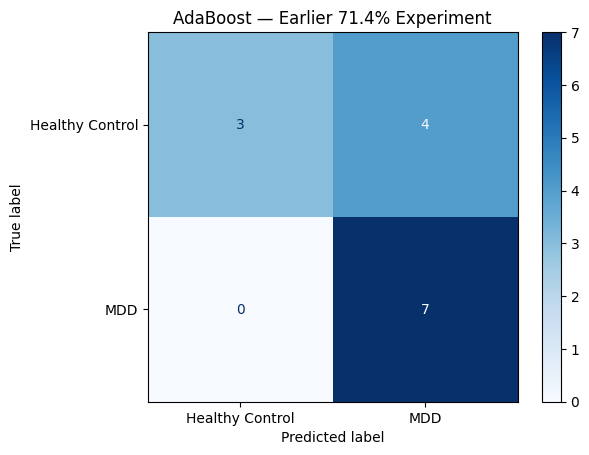

In [16]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_ada,
    labels=[0, 1],
    display_labels=["Healthy Control", "MDD"],
    cmap="Blues"
)

plt.title("AdaBoost — Earlier 71.4% Experiment")
plt.show()

## 16. Calculate ROC-AUC

In [17]:
if hasattr(best_ada_model, "predict_proba"):
    y_probability = best_ada_model.predict_proba(X_test)[:, 1]
    print("ROC-AUC:", roc_auc_score(y_test, y_probability))
else:
    print("This fitted estimator does not provide predict_proba.")

ROC-AUC: 0.673469387755102


## 17. Save the fitted model and feature order

The saved pipeline includes the median imputer and AdaBoost estimator. The feature order is stored so future recordings must be transformed into exactly the same 51 features in the same order.

In [18]:
model_package = {
    "model": best_ada_model,
    "model_name": "AdaBoost",
    "feature_columns": X.columns.tolist(),
    "sampling_rate": SAMPLING_RATE,
    "channel_names": CHANNEL_NAMES,
    "filter_band_hz": [1, 40],
    "label_meaning": {
        0: "Healthy Control (HC)",
        1: "Major Depressive Disorder group (MDD)"
    }
}

MODEL_FILE = "adaboost_eeg_model.joblib"
joblib.dump(model_package, MODEL_FILE)
joblib.dump(model_package, "adaboost_71pct_experiment.joblib")

print("Saved:", MODEL_FILE)

Saved: adaboost_71pct_experiment.joblib


## 18. Final interpretation and limitations

- The earlier experiment achieved **71.43% accuracy** on 14 held-out participants when using the original 51 features, the specified stratified split, and the AdaBoost GridSearchCV pipeline.
- Its confusion matrix was `[[3, 4], [0, 7]]`: it identified all 7 MDD participants but misclassified 4 of the 7 healthy controls.
- The test set is very small, so one prediction changes accuracy by about 7.14 percentage points.
- The test set has been examined repeatedly during development. Therefore, 71.43% is a historical exploratory result, not an untouched final estimate.
- The earlier workflow filled missing numeric values before splitting, which can cause data leakage. A more rigorous future analysis should impute within each training fold and use nested cross-validation.
- This model is for academic research only. It is not a clinical diagnostic tool.

**Important:** This notebook is intentionally the reproduction of the earlier 71.43% experiment. It is not the nested-CV final research notebook. Keep the two experiments separate in your project report and describe their different validation procedures honestly.